# 08 · XGBoost challenger models (Milestone 10)

**Goal:** build **fairly tuned XGBoost models** for claim frequency, claim severity and pure premium, on the same data, the same features and the same validation design as the GLMs (notebooks 05–07), so Milestone 11 can compare them properly and Milestone 12 can explain them with SHAP.

| Model | XGBoost objective | GLM it challenges | Modelling unit |
|---|---|---|---|
| Frequency | `count:poisson`, log(earned exposure) in `base_margin` | Poisson GLM (notebook 05) | rating cells with exposure > 0 |
| Severity | `reg:gamma` | Gamma GLM (notebook 06) | individual paid claims, uncapped (the GLM's large-loss treatment) |
| Pure premium | `reg:tweedie`, power 1.7 | Tweedie GLM (notebook 07) | rating cells, loss cost weighted by exposure |

What this notebook does:
1. **Tuning without leakage:** randomized search, each setting scored by leave-one-year-out on **2010–2020 only**, with early stopping on the average over the 11 held-out years.
2. **Final settings** for each model.
3. **Geography (Question 7):** does XGBoost find county group or the Tidewater flag useful on unseen years? Each geography variant gets its own tuned settings.
4. **Monotonic constraints:** forcing actuarially sensible directions, constrained vs unconstrained.
5. **Held-out performance:** development years out of fold and the one-time 2021–2025 holdout: A/E overall and by year, deviance, Gini, lift charts. Plus a **short preview against the GLMs** (the full comparison is Milestone 11).
6. **A first look inside:** gain-based feature importance and the strongest interactions.
7. **Pure premium checks** (double lift, segment balance), two sensitivity checks, and saving the models.

**Code:** `src/models/xgb_models.py` (this notebook calls it; tuning ran through its command line). **Write-up:** `reports/07_xgboost.md`.

> Area-level analysis of aggregated public data. Every number describes the average for a *group* of similar insured buildings, never a prediction for an individual property.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import TwoSlopeNorm
import numpy as np
import pandas as pd
import xgboost as xgb

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import validation as val
from models import frequency_glm as fg
from models import severity_glm as sv
from models import pure_premium as pp
from models import xgb_models as X

warnings.filterwarnings("ignore")
FIG = ROOT / "reports" / "figures"
REP = ROOT / "reports"
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"     # XGBoost / GLM or 2nd variant / 3rd
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "font.size": 9.5,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "legend.frameon": False, "text.usetex": False, "text.parse_math": False,
})

def save(fig, name):
    path = FIG / f"08_{name}.png"
    fig.savefig(path)
    print(f"saved {path.relative_to(ROOT)}")

def log_axis(ax, lo, hi, axis="y", ticks=(0.05, 0.1, 0.25, 0.5, 1, 2, 4, 8)):
    a = ax.yaxis if axis == "y" else ax.xaxis
    (ax.set_yscale if axis == "y" else ax.set_xscale)("log")
    (ax.set_ylim if axis == "y" else ax.set_xlim)(lo, hi)
    a.set_major_locator(mticker.FixedLocator([t for t in ticks if lo <= t <= hi]))
    a.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:g}"))
    a.set_minor_locator(mticker.NullLocator())

LABELS = {"flood_zone_group": "Flood zone", "occupancy_group": "Occupancy", "floors_group": "Floors",
          "elevated": "Elevated", "primary_residence": "Primary residence", "post_firm": "Post-FIRM",
          "construction_band": "Year built", "building_coverage_band": "Building coverage",
          "coastal_tidal": "Tidewater", "county_group": "County group"}
SHORT = {"A/V high risk": "A/V", "B/C/X moderate-low risk": "B/C/X", "True": "yes", "False": "no",
         "$0 (contents only)": "$0", "under $100K": "<$100K", "$100K-$249K": "$100-249K",
         "$250K or more": "$250K+", "2000 or later": "2000+", "before 1960": "<1960",
         "single-unit residential": "single", "multi-unit residential": "multi", "non-residential": "non-res"}
KINDS = list(X.KINDS)
KLABEL = {"frequency": "Frequency (count:poisson)", "severity": "Severity (reg:gamma)",
          "tweedie": "Pure premium (reg:tweedie, p = 1.7)"}
RETUNE = False   # True re-runs the searches (about 2-3 hours); False reads the saved results
print("xgboost", xgb.__version__)

xgboost 3.4.1


## 0. Data and the leakage guard
- **Frequency and Tweedie:** the rating-cell table, summed over rows that share all 10 features and the year (county itself dropped, `county_group` kept): 170,806 rows. The 111 zero-exposure ("unmatched") cells are excluded, as for the GLMs. Their losses are added back to the Tweedie by its off-balance factor, as in Milestone 9.
- **Severity:** the 9,553 individual paid claims with building + contents > $0, unmatched claims included, ICC excluded (added back with the 1.0092 bridge when building a pure premium).
- **Every model is scored on these same rows**, including the GLMs in section 5, so deviances are comparable.

**How the year is handled (the same idea as the GLMs' year factor).** XGBoost's `base_margin` is a fixed starting value for each row, on the log scale, that the trees add to. It's XGBoost's version of the GLM **offset**. For frequency it holds log(earned exposure), so the trees predict claims *per policy-year*. It also holds the **log of that calendar year's average level** (claim rate, claim size or loss cost), estimated from the training years only. So storm years don't get mixed up with building features, and a year the model hasn't seen is predicted at the **average-year level**. Year is never a tree feature.

In [2]:
if RETUNE:
    for k in KINDS:
        X.cmd_tune(k)
        X.cmd_compare(k)

cells = X.load_cell_table()                     # frequency + Tweedie rows (exposure > 0)
unm = X.unmatched_losses_by_year()              # losses in zero-exposure cells, by year
claims_all = sv.load_claims(verbose=False)      # ALL paid claims (incl. ICC-only) for the ICC bridge
sevdf = X.load_severity_table()                 # severity rows (building + contents > $0)
raw_cells = pd.read_parquet(X.CELLS_PATH)       # the Tweedie GLM and freq x sev GLM use the raw cells
S = X.read_settings()
DATA = {"frequency": (cells, None), "severity": (sevdf, None), "tweedie": (cells, unm)}
TARGET = {k: X.KINDS[k]["target"] for k in KINDS}

# Leakage check: every tuning and selection fold sits inside 2010-2020 only.
for y, tr, te in val.leave_one_year_out(cells, val.DEV_YEARS):
    assert tr["year"].max() <= val.LAST_TRAIN_YEAR and set(te["year"]) == {y} and y <= val.LAST_TRAIN_YEAR
print(f"Development folds: {len(val.DEV_YEARS)} (test years {val.DEV_YEARS[0]}-{val.DEV_YEARS[-1]}); "
      f"2021-2025 is used only in section 5's one-time holdout.")
print(f"Unmatched-cell losses (Tweedie off-balance only): ${unm.sum():,.0f}")

Cell table: 170,806 rows (252,420 cells with exposure), 1,482,413 policy-years, 9,462 paid claims, $289,148,902.
Severity table: 9,553 paid claims, $289,883,404 building + contents.


Development folds: 11 (test years 2010-2020); 2021-2025 is used only in section 5's one-time holdout.
Unmatched-cell losses (Tweedie off-balance only): $3,537,079


## 1. Tuning: randomized search on the development years
**What is being tuned.** A boosted model has settings that are not learned from the data but chosen by us, called **hyperparameters**:
- `max_depth`: how many questions each tree may ask in a row (2 = simple, 6 = very specific groups).
- `learning_rate`: what fraction of each new tree is added (small = cautious, needs more trees).
- `n_estimators`: how many trees. Chosen by **early stopping** (below).
- `min_child_weight`: the smallest "amount of evidence" a leaf may have. Its unit is the objective's **hessian**: roughly expected claims for Poisson, claims for Gamma, and exposure-weighted loss cost for the Tweedie, so the three ranges differ.
- `subsample` / `colsample_bytree`: each tree sees only a random share of rows / features (adds randomness that fights over-fitting).
- `reg_lambda`, `reg_alpha`: penalties that shrink leaf values toward zero; `gamma`: the smallest improvement a split must bring.

**How (decided before running):**
- **Randomized search:** draw random settings from sensible ranges. That's 40 settings for frequency and severity, and 20 for the slower-to-pay-off Tweedie.
- **Score:** each setting is scored by leave-one-year-out on 2010–2020: 11 fits, each predicting one unseen year. The score is the **mean re-based deviance improvement over the no-features model**, each year counting once, exactly the metric the GLMs were chosen on. **2021–2025 is never touched.**
- **Early stopping on the mean:** the 11 fold models grow side by side, 10 trees at a time (20 for severity). After each step every held-out year is scored and averaged. When the average hasn't improved for 150 trees, stop. The best tree count is `n_estimators`.
- **A separate search for each geography variant** (no geography / + Tidewater / + Tidewater + county group), with the same random draws. A dry run showed county group makes frequency much worse on unseen years. A search with it included picks settings that work around it, so the geography test (section 3) is only fair if each variant gets its own best settings.
- **Tie rule:** among settings within 0.1 points of the best, take the simplest (shallowest trees, then fewest trees).

**What the search found** (table and chart below): 300 settings × 11 folds took about 3.5 hours on this laptop.
- **The geography variant matters more than any single setting:** for frequency, every one of the 40 "no geography" draws beats the best county-group draw. For severity it's the reverse: every county-group draw beats the same draw without geography.
- **Learning rate and depth matter little** once early stopping picks the tree count: the clouds are flat across them.
- **min_child_weight** matters most: frequency prefers small leaves (about 1–20 expected claims), and severity prefers large ones (about 60–120 claims).

In [3]:
tun = pd.concat([pd.read_csv(X.tuning_csv(k, v)).assign(kind=k, variant=v)
                 for k in KINDS for v in X.GEOGRAPHY_VARIANTS], ignore_index=True)
summ = tun.groupby(["kind", "variant"], sort=False).agg(
    configs=("score", "size"), best=("score", "max"), median=("score", "median"), worst=("score", "min"),
    median_trees=("best_rounds", "median"), minutes=("seconds", lambda s: s.sum() / 60)).round(2)
print("Mean held-out improvement (%) over the 11 development years, per random setting:")
print(summ.to_string())
print(f"\nTotal search time: {tun['seconds'].sum() / 60:.0f} minutes on this laptop "
      f"({len(tun)} settings x 11 folds).")
for k in KINDS:
    v = S[k]["geography_test"]["chosen"]
    t = tun[(tun.kind == k) & (tun.variant == v)].sort_values("score", ascending=False).head(5)
    print(f"\n{KLABEL[k]}: top 5 settings for '{v}'")
    print(t[["config", *X.PARAM_COLS, "best_rounds", "score", "non_cat", "cat", "gini"]].round(3).to_string(index=False))

Mean held-out improvement (%) over the 11 development years, per random setting:
                                      configs   best  median  worst  median_trees  minutes
kind      variant                                                                         
frequency no geography                     40   6.83    6.35   5.87         150.0    22.16
          + Tidewater                      40   6.44    5.63   5.01         130.0    36.87
          + Tidewater + county group       40   5.18    4.52   3.85          90.0    34.67
severity  no geography                     40  23.51   23.24  22.60         460.0    20.44
          + Tidewater                      40  23.96   23.69  23.17         500.0    23.90
          + Tidewater + county group       40  25.46   24.93  23.47         680.0    28.28
tweedie   no geography                     20  16.73   16.26  14.06         135.0    11.55
          + Tidewater                      20  17.09   16.42  14.79         120.0    17.39
         

saved reports\figures\08_tuning_search.png


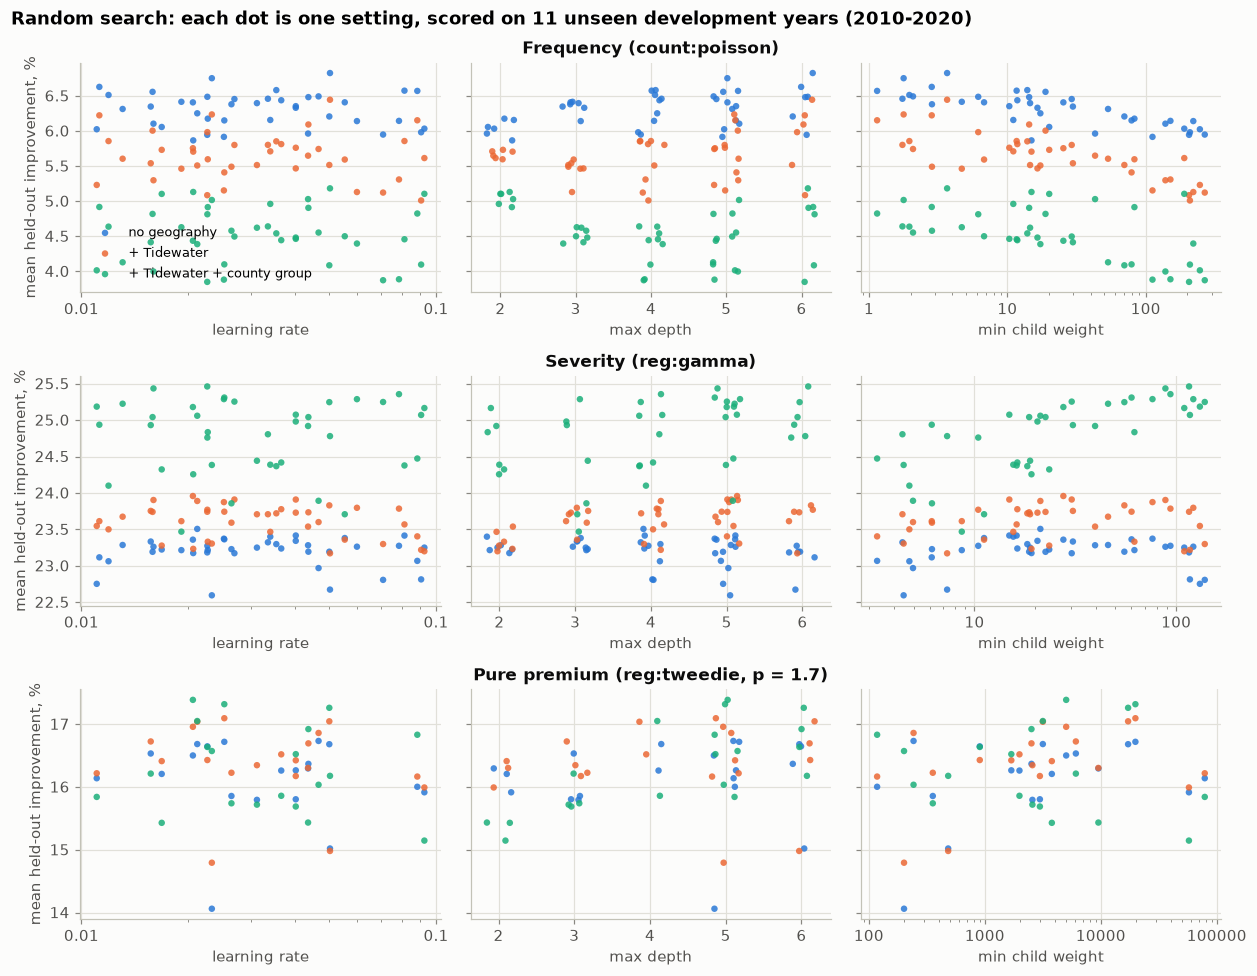

In [4]:
VCOL = dict(zip(X.GEOGRAPHY_VARIANTS, [BLUE, ORANGE, AQUA]))
fig, axes = plt.subplots(3, 3, figsize=(11.5, 9), sharey="row")
rng = np.random.default_rng(0)
for i, k in enumerate(KINDS):
    t = tun[tun.kind == k]
    for j, (col, lab, logx) in enumerate([("learning_rate", "learning rate", True), ("max_depth", "max depth", False),
                                          ("min_child_weight", "min child weight", True)]):
        ax = axes[i, j]
        for v, c in VCOL.items():
            tv = t[t.variant == v]
            xv = tv[col] + (rng.uniform(-0.18, 0.18, len(tv)) if col == "max_depth" else 0)
            ax.scatter(xv, tv["score"], s=18, color=c, alpha=0.85, edgecolor="none", label=v)
        if logx:
            ax.set_xscale("log")
            ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:g}"))
        ax.set_xlabel(lab)
        if j == 0:
            ax.set_ylabel("mean held-out improvement, %")
        if j == 1:
            ax.set_title(KLABEL[k], loc="center")
axes[0, 0].legend(loc="lower left", fontsize=8.5)
fig.suptitle("Random search: each dot is one setting, scored on 11 unseen development years (2010-2020)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "tuning_search")
plt.show()

**Early stopping and over-fitting.** Re-running the chosen settings shows the curve the stopping rule watched. At first each extra tree learns real patterns and the held-out score rises. Past the peak, new trees start fitting the training years' noise (which storm hit which cells), and the score on unseen years falls. That's **over-fitting**. Stopping at the peak of the *average over 11 unseen years* picks the tree count without ever looking at 2021–2025.

*Honest caveat:* choosing the best of many settings and tree counts on the same 11 folds makes that best score slightly optimistic (**selection optimism**). The one-time holdout in section 5 is the clean check.

frequency: best 6.75% at 170 trees (settings file: 170); stopped at 320 (68s)


severity: best 25.43% at 940 trees (settings file: 940); stopped at 1100 (49s)


tweedie: best 17.44% at 120 trees (settings file: 120); stopped at 270 (67s)


saved reports\figures\08_early_stopping.png


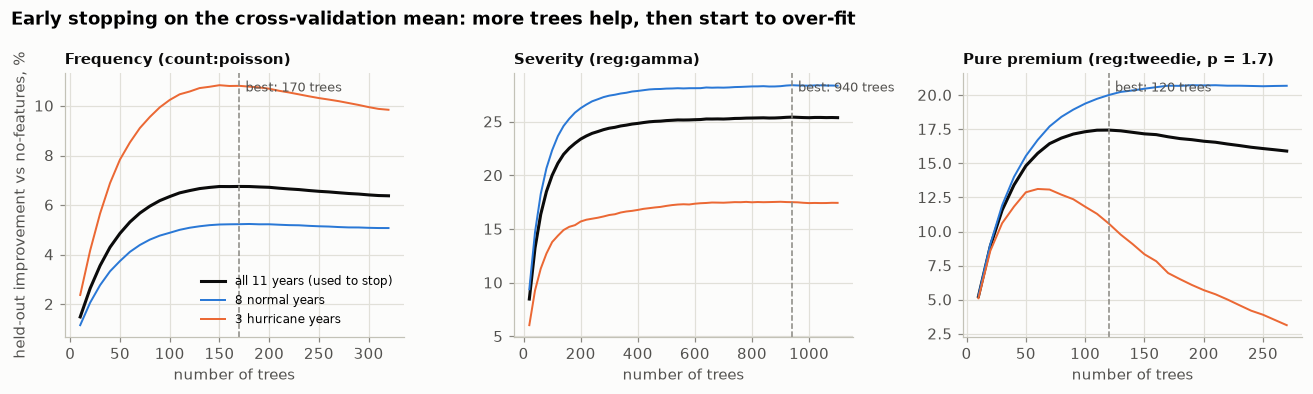

In [5]:
CURVES = {}
for k in KINDS:
    s, (df, u) = S[k], DATA[k]
    t0 = time.time()
    cv = X.cv_lockstep(df, k, s["params"], s["features"], s["monotone"], unmatched=u)
    CURVES[k] = cv
    print(f"{k}: best {cv['best_score']:.2f}% at {cv['best_rounds']} trees (settings file: {s['n_rounds']}); "
          f"stopped at {cv['stopped_at']} ({time.time() - t0:.0f}s)")
    assert cv["best_rounds"] == s["n_rounds"], "the re-run should reproduce the saved tree count"

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, k in zip(axes, KINDS):
    c = CURVES[k]["curve"]
    g = c.groupby("round")
    ax.plot(g["improvement_rebased_pct"].mean(), color=INK, lw=2, label="all 11 years (used to stop)")
    ax.plot(c[~c.cat_year].groupby("round")["improvement_rebased_pct"].mean(), color=BLUE, lw=1.3, label="8 normal years")
    ax.plot(c[c.cat_year].groupby("round")["improvement_rebased_pct"].mean(), color=ORANGE, lw=1.3, label="3 hurricane years")
    b = CURVES[k]["best_rounds"]
    ax.axvline(b, color=MUTED, ls="--", lw=1)
    ax.annotate(f"best: {b} trees", (b, ax.get_ylim()[1]), xytext=(4, -12), textcoords="offset points", color=INK_2, fontsize=8.5)
    ax.set_title(KLABEL[k], fontsize=10)
    ax.set_xlabel("number of trees")
axes[0].set_ylabel("held-out improvement vs no-features, %")
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Early stopping on the cross-validation mean: more trees help, then start to over-fit",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "early_stopping")
plt.show()

## 2. Final settings
These are the settings carried forward (after the geography and monotone decisions in sections 3–4). They're saved in `models/xgb_settings.json` for Milestones 11–12.

In [6]:
rows = []
for k in KINDS:
    s = S[k]
    rows.append({"model": k, "objective": s["objective"], "geography": s["geography_test"]["chosen"],
                 "features": len(s["features"]), "monotone constraints": "yes" if s["monotone"] else "no",
                 **{c: round(v, 4) if isinstance(v, float) else v for c, v in s["params"].items()},
                 "n_estimators (trees)": s["n_rounds"], "dev-LOYO improvement %": round(s["dev_loyo_score"], 2)})
settings_tbl = pd.DataFrame(rows).set_index("model").T
print(settings_tbl.to_string())
settings_tbl.to_csv(REP / "07_xgb_final_settings.csv")

model                       frequency                    severity                     tweedie
objective               count:poisson                   reg:gamma                 reg:tweedie
geography                no geography  + Tidewater + county group  + Tidewater + county group
features                            8                          10                          10
monotone constraints               no                          no                         yes
max_depth                           5                           5                           5
learning_rate                  0.0233                       0.016                      0.0206
min_child_weight               1.7789                     88.3764                   5025.1528
subsample                      0.7069                      0.8278                      0.7666
colsample_bytree               0.9572                      0.7438                      0.8871
reg_lambda                     0.7251                      0

## 3. Geography: does XGBoost find it useful on unseen years? (Question 7)
**The test.** Three feature sets, each with its own tuned settings:
1. the 8 building features;
2. + the Tidewater flag (the recommended coastal definition);
3. + Tidewater + county group (32 counties + 3 pools, one-hot).

**The same keep rule as the GLMs:** a geography step is kept only if it improves the mean development-LOYO score **and** is better in at least 6 of the 11 years. *Census coastal* isn't tested (Task 5 recommended Tidewater instead). The 2021–2025 holdout is shown for every variant after the choice, for information only.

**Result:**
- **Frequency: no geography.** Tidewater makes unseen years worse by 0.31 points (better in 5 of 11). County group makes them worse by 1.65 points (better in only 1 of 11), and none of the 40 county-group settings beats the no-geography ones. This matches the GLM finding: **county frequency differences are mostly storm noise.** The holdout agrees (Tidewater 4.38% vs 4.34%, no real change; county 3.08%).
- **Severity: Tidewater + county group.** Tidewater adds 0.47 points (7 of 11), county group a further 1.54 (8 of 11). The holdout confirms: 23.7% vs 21.1% with no geography. The GLM said no, but the trees, which can let a county's effect depend on occupancy and zone, find **real county differences in claim size**. That's consistent with Milestone 9's Bühlmann–Straub result (credible county severity, no credible county frequency).
- **Pure premium (Tweedie): Tidewater + county group**, each step narrowly (+0.36 in 6 of 11; +0.35 in 7 of 11). On the holdout the gain is large (14.0% → 20.8%).

In [7]:
geo = {k: pd.read_csv(REP / f"07_xgb_geography_{k}.csv") for k in KINDS}
steps = {k: pd.read_csv(REP / f"07_xgb_geography_steps_{k}.csv") for k in KINDS}
gfold = {k: pd.read_csv(REP / f"07_xgb_geography_folds_{k}.csv") for k in KINDS}
for k in KINDS:
    print(f"\n{KLABEL[k]}: each variant with its OWN best settings (development LOYO, 11 years)")
    print(geo[k][["variant", "config", "max_depth", "learning_rate", "best_rounds", "score", "non_cat", "cat", "gini",
                  "median_config_score", "draws_better_than_no_geography", "draws"]].round(3).to_string(index=False))
    print("Keep rule steps (better mean AND >= 6 of 11 years):")
    print(steps[k].round(3).to_string(index=False))
    print("-> chosen:", S[k]["geography_test"]["chosen"])

# Once the choice is frozen: the 2021-2025 holdout for every variant, scored once, for information.
geo_hold = []
for k in KINDS:
    df, u = DATA[k]
    for _, r in geo[k].iterrows():
        sc, _, _ = X.evaluate(df, k, X.params_of(r), int(r["best_rounds"]), r["features"].split("|"), None,
                              holdout=True, unmatched=u)
        p = sc[sc.test_year == "pooled"].iloc[0]
        geo_hold.append({"model": k, "variant": r["variant"], "dev-LOYO %": r["score"],
                         "holdout 2021-25 %": p["improvement_rebased_pct"], "holdout Gini": p["gini"]})
geo_hold = pd.DataFrame(geo_hold)
print("\nHoldout 2021-2025 (after the choice; not used for it):")
print(geo_hold.round(3).to_string(index=False))
geo_hold.to_csv(REP / "07_xgb_geography_holdout.csv", index=False)


Frequency (count:poisson): each variant with its OWN best settings (development LOYO, 11 years)
                   variant  config  max_depth  learning_rate  best_rounds  score  non_cat    cat  gini  median_config_score  draws_better_than_no_geography  draws
              no geography      17          5          0.023          170  6.752    5.230 10.811 0.341                6.351                               0     40
               + Tidewater       5          6          0.050           80  6.445    5.117  9.987 0.341                5.631                               0     40
+ Tidewater + county group       1          2          0.093           30  5.105    3.348  9.791 0.292                4.521                               0     40
Keep rule steps (better mean AND >= 6 of 11 years):
        from                         to  mean_diff_pts  folds_better  folds  kept
no geography                + Tidewater         -0.307             5     11 False
no geography + Tidewater + county g


Holdout 2021-2025 (after the choice; not used for it):
    model                    variant  dev-LOYO %  holdout 2021-25 %  holdout Gini
frequency               no geography       6.752              4.344         0.326
frequency                + Tidewater       6.445              4.384         0.337
frequency + Tidewater + county group       5.105              3.077         0.276
 severity               no geography      23.415             21.117         0.327
 severity                + Tidewater      23.890             20.584         0.317
 severity + Tidewater + county group      25.435             23.656         0.349
  tweedie               no geography      16.684             14.024         0.511
  tweedie                + Tidewater      17.039             19.904         0.626
  tweedie + Tidewater + county group      17.387             20.804         0.659


saved reports\figures\08_geography.png


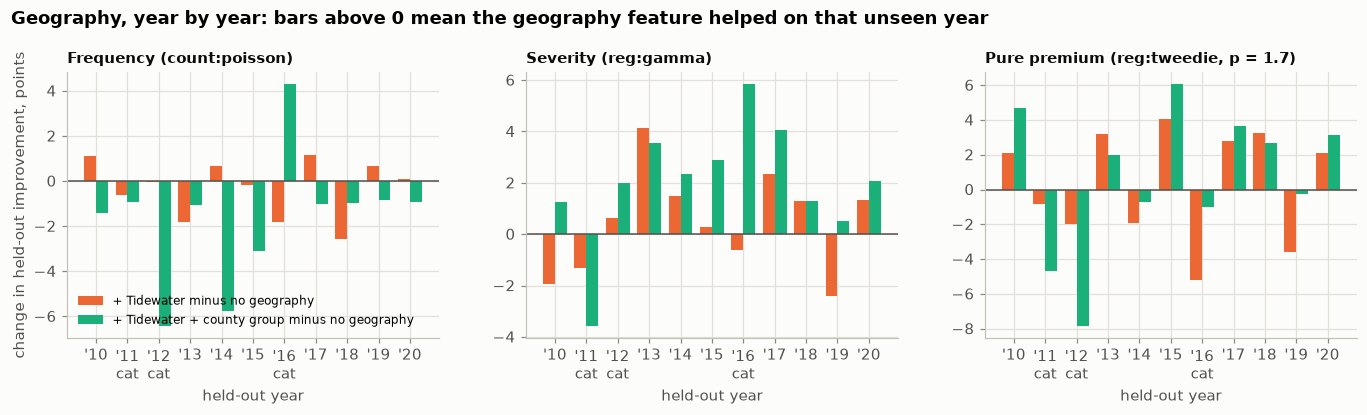

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8), sharey=False)
names = list(X.GEOGRAPHY_VARIANTS)
for ax, k in zip(axes, KINDS):
    g = gfold[k].pivot(index="test_year", columns="variant", values="improvement_rebased_pct")
    yrs = g.index.to_numpy()
    for i, (v, c) in enumerate([(names[1], ORANGE), (names[2], AQUA)]):
        ax.bar(yrs + (i - 0.5) * 0.38, g[v] - g[names[0]], width=0.38, color=c, label=f"{v} minus no geography")
    ax.axhline(0, color=INK_2, lw=1)
    ax.set_xticks(yrs)
    ax.set_xticklabels([f"'{str(y)[2:]}" + ("\ncat" if y in val.CAT_YEARS else "") for y in yrs])
    ax.set_title(KLABEL[k], fontsize=10)
    ax.set_xlabel("held-out year")
axes[0].set_ylabel("change in held-out improvement, points")
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Geography, year by year: bars above 0 mean the geography feature helped on that unseen year",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "geography")
plt.show()

## 4. Monotonic constraints
**What they are.** A monotonic constraint forces the model's prediction to move in one direction only as a feature goes up, for **every** combination of the other features. Trees are otherwise free to produce odd patterns, e.g. a higher coverage limit giving a *smaller* expected claim in some corner of the data, which no actuary could defend.

**Chosen on actuarial grounds** (codes: zone 0 = A/V, 1 = B/C/X; year built 0 = before 1960 … 3 = 2000+; coverage 0 = $0 … 3 = $250K+):
- **Frequency:** B/C/X zone, elevated, newer, post-FIRM buildings never claim *more often* (−1).
- **Severity:** a higher coverage limit never *lowers* claim size (+1); elevated and B/C/X never *raise* it (−1). Year built, floors and occupancy stay free, because the GLM shows real non-monotone patterns (e.g. the 1960–79 peak).
- **Pure premium (Tweedie):** zone, elevated, post-FIRM (−1), coverage (+1). Year built stays free here, because the GLM loss cost peaks in 1960–79 (3.5×) above before-1960 (2.8×).

**Rule (decided before running):** the top 5 tuned settings are re-run with the constraints (tree count re-picked). **Use the constraints unless they cost more than 0.25 points of mean development improvement on the tuned setting, or are worse in 8 or more of the 11 years.** Constraints add defensibility and stability, so a small cost is worth paying.

**Result:**
- **Frequency: unconstrained, by the rule, but a close call.** The constraints *raise* the mean score (+0.10 on the tuned setting, +0.10 to +0.34 on all five). But almost all of that gain is 2016 (Hurricane Matthew: about +5 points), and they're worse in 9 of the 11 years. The pre-stated rule protects against exactly this "one storm year decides" pattern.
  - Cost of the choice: the unconstrained model's average elevated effect is **1.01** (elevated very slightly *raises* frequency), which isn't defensible. Milestone 11 should re-check this on all 16 years.
- **Severity: unconstrained.** The constraints cost 0.54–0.66 points on every one of the top 5 settings (more than the 0.25 allowance). The constrained coverage curve is steeper; the trees prefer flatter steps in some corners.
- **Pure premium (Tweedie): constrained** (+0.05 points, 5 of 11 years: no cost, so they're kept).
- In the chart, zone, year built and post-FIRM effects agree closely with the GLMs. The XGBoost Tweedie's coverage effect is almost flat (1.0–1.2×), while frequency × severity GLMs give 2.5–3.6×. The same low weight on high-cost cells that hurt the GLM Tweedie (Milestone 9) shows up here.

In [9]:
mono = {k: pd.read_csv(REP / f"07_xgb_monotone_{k}.csv") for k in KINDS}
for k in KINDS:
    m = mono[k]
    piv = m.pivot(index="config", columns="variant", values="score")
    piv["constrained - unconstrained (pts)"] = piv["constrained"] - piv["unconstrained"]
    t = S[k]["monotone_test"]
    print(f"\n{KLABEL[k]}: constraints {t['constraints']}")
    print(piv.round(3).to_string())
    p = t["chosen_config_pair"]
    print(f"Rule on the tuned config: {p['mean_diff_pts']:+.2f} pts, constrained better in {p['folds_better']} of "
          f"{p['folds']} years -> {'USE constraints' if t['use_constraints'] else 'no constraints'}")


Frequency (count:poisson): constraints {'flood_zone_group': -1, 'elevated': -1, 'construction_band': -1, 'post_firm': -1}
variant  constrained  unconstrained  constrained - unconstrained (pts)
config                                                                
5              7.042          6.825                              0.216
17             6.855          6.752                              0.103
22             6.855          6.582                              0.272
34             6.913          6.574                              0.339
36             6.880          6.628                              0.252
Rule on the tuned config: +0.10 pts, constrained better in 2 of 11 years -> no constraints

Severity (reg:gamma): constraints {'building_coverage_band': 1, 'elevated': -1, 'flood_zone_group': -1}
variant  constrained  unconstrained  constrained - unconstrained (pts)
config                                                                
12            24.685         25.310       

saved reports\figures\08_monotone_pd.png


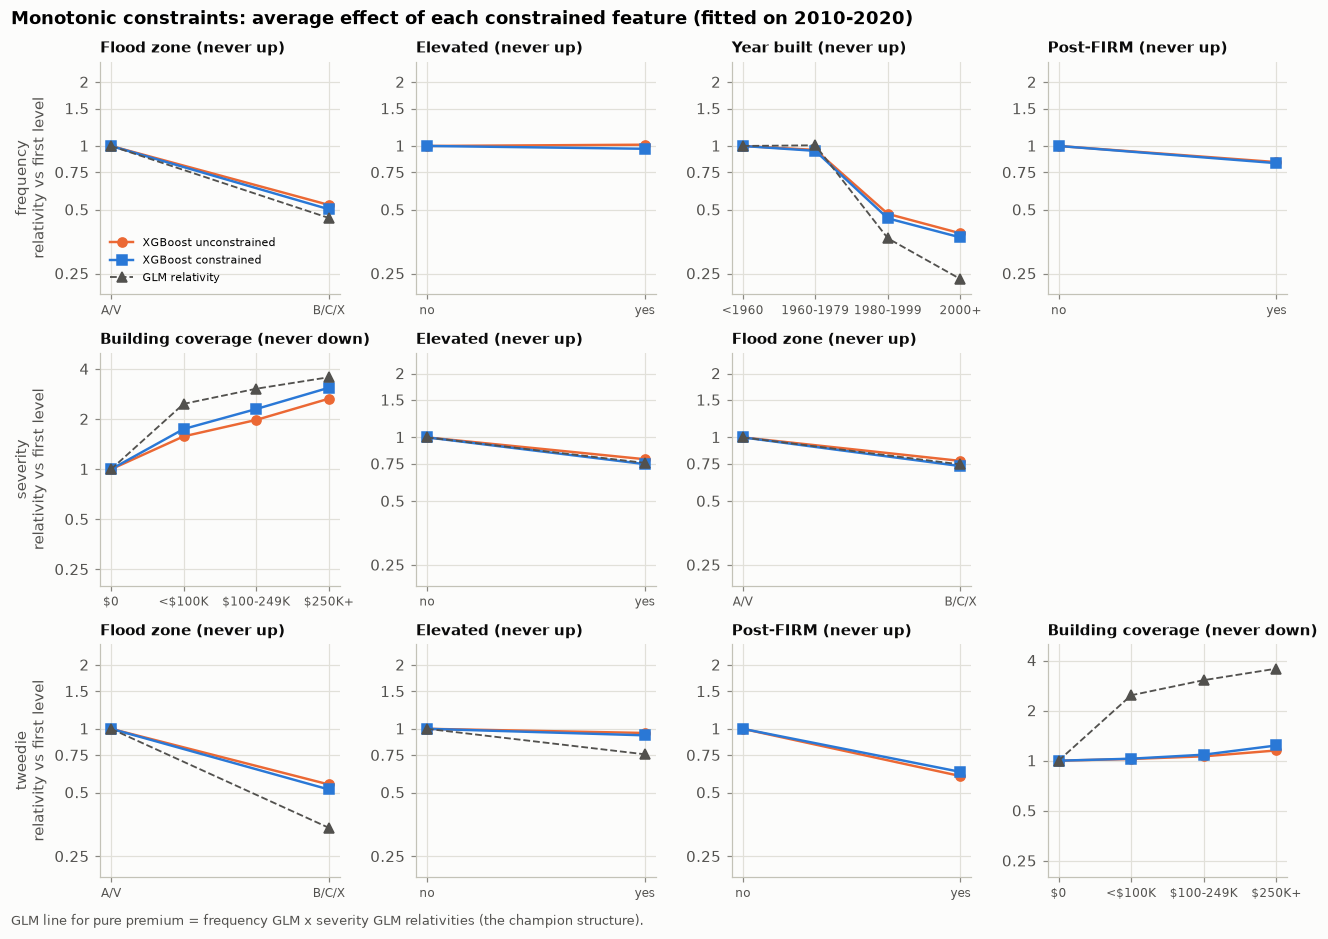

constrained partial dependence is monotone in every case
variant                                                   unconstrained  constrained
model     feature                level                                              
frequency flood_zone_group       A/V high risk                    1.000        1.000
                                 B/C/X moderate-low risk          0.527        0.503
          elevated               False                            1.000        1.000
                                 True                             1.014        0.970
          construction_band      before 1960                      1.000        1.000
                                 1960-1979                        0.958        0.948
                                 1980-1999                        0.478        0.455
                                 2000 or later                    0.387        0.370
          post_firm              False                            1.000        1.000
        

In [10]:
# Partial dependence of the constrained features: the model's average relativity per level,
# constrained vs unconstrained (same settings, own tree counts), against the GLM relativities.
FG = fg.load_model_json(ROOT / "models" / "frequency_glm.json")
SG = sv.load_model_json(ROOT / "models" / "severity_glm.json")
FF, SF = list(FG.spec.features), list(SG.spec.features)
FB, SB = pp.bases_without_year(FG.spec), pp.bases_without_year(SG.spec)
TWF = json.loads((ROOT / "models" / "pure_premium.json").read_text())["tweedie_challenger"]["features"]

def glm_rel(kind, f, lvl):
    get = lambda m: float(np.exp(m.params.get(f"{f}[{lvl}]", 0.0)))
    return {"frequency": get(FG), "severity": get(SG), "tweedie": get(FG) * get(SG)}[kind]

def in_glm(kind, f):
    return {"frequency": f in FF, "severity": f in SF, "tweedie": f in FF or f in SF}[kind]

WEIGHT = {"frequency": "exposure", "severity": None, "tweedie": "exposure"}
PD_ROWS = []
ncol = max(len(X.MONOTONE[k]) for k in KINDS)
fig, axes = plt.subplots(3, ncol, figsize=(3.0 * ncol, 8.4))
for i, k in enumerate(KINDS):
    s, (df, u) = S[k], DATA[k]
    dev = df[df.year <= val.LAST_TRAIN_YEAR]
    mt = mono[k].set_index(["config", "variant"])
    cfg = S[k]["config"]
    fits = {v: X.fit_xgb(dev, k, s["params"], int(mt.loc[(cfg, v), "best_rounds"]), s["features"],
                         X.MONOTONE[k] if v == "constrained" else None, unmatched_losses=X._unm(u, val.DEV_YEARS))
            for v in ("unconstrained", "constrained")}
    for j in range(ncol):
        ax = axes[i, j]
        feats = list(X.MONOTONE[k])
        if j >= len(feats):
            ax.axis("off")
            continue
        f = feats[j]
        lv = X.levels_of(f, dev)
        base = lv[0]
        xs = np.arange(len(lv))
        for v, c, mk in (("unconstrained", ORANGE, "o"), ("constrained", BLUE, "s")):
            pdv = X.partial_dependence(fits[v], dev, f, WEIGHT[k], base)
            ax.plot(xs, pdv.to_numpy(), color=c, marker=mk, lw=1.6, label=f"XGBoost {v}")
            PD_ROWS += [{"model": k, "feature": f, "level": l, "variant": v, "relativity": pdv[l]} for l in lv]
        if in_glm(k, f):
            g = np.array([glm_rel(k, f, l) for l in lv])
            ax.plot(xs, g / g[0], color=INK_2, ls="--", marker="^", lw=1.2, label="GLM relativity")
        ax.set_xticks(xs)
        ax.set_xticklabels([SHORT.get(l, l) for l in lv], fontsize=8)
        arrow = "never up" if X.MONOTONE[k][f] < 0 else "never down"
        ax.set_title(f"{LABELS[f]} ({arrow})", fontsize=9.5)
        if f == "building_coverage_band":
            log_axis(ax, 0.2, 5, ticks=(0.25, 0.5, 1, 2, 4))
        else:
            log_axis(ax, 0.2, 2.5, ticks=(0.25, 0.5, 0.75, 1, 1.5, 2))
        if j == 0:
            ax.set_ylabel(f"{k}\nrelativity vs first level")
axes[0, 0].legend(fontsize=7.5, loc="lower left")
fig.text(0.01, -0.01, "GLM line for pure premium = frequency GLM x severity GLM relativities (the champion structure).",
         fontsize=8.5, color=INK_2)
fig.suptitle("Monotonic constraints: average effect of each constrained feature (fitted on 2010-2020)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "monotone_pd")
plt.show()
pd_tbl = pd.DataFrame(PD_ROWS)
# The constrained curves really are monotone:
for (k, f), g in pd_tbl[pd_tbl.variant == "constrained"].groupby(["model", "feature"]):
    d = np.diff(g["relativity"].to_numpy())
    assert (d * X.MONOTONE[k][f] >= -1e-9).all(), (k, f)
print("constrained partial dependence is monotone in every case")
print(pd_tbl.pivot_table(index=["model", "feature", "level"], columns="variant", values="relativity", sort=False).round(3).to_string())

## 5. Held-out performance, with a short preview against the GLMs
Two kinds of unseen data:
- **Development years, out of fold:** each of 2010–2020 predicted by a model trained on the other 10 years, with the final settings.
- **The one-time holdout:** trained on 2010–2020, predicting 2021–2025.

The GLMs are refitted inside the same folds with their final features (frequency: zone, year built, floors; severity: the 7 Milestone 8 features; Tweedie: the union, p = 1.7), via the same scoring code and rows.

**Metrics:**
- **Deviance** (Poisson for frequency, Gamma for severity, Tweedie at the common p = 1.5 yardstick for pure premium), shown as % improvement over the no-features model, *re-based* so the year's overall level is removed (no model can know whether a hurricane is coming).
- **Gini** (ranking quality).
- **Raw actual ÷ expected** (calibration of the average-year level).

*This is a preview only; Milestone 11 does the full comparison* (16-year LOYO, significance across years, double lifts, segment checks).

**Result (table below):** XGBoost is ahead on all three models, on both kinds of unseen data.

| | Dev-LOYO XGB | Dev-LOYO GLM | Years XGB wins | Holdout XGB | Holdout GLM |
|---|---|---|---|---|---|
| Frequency | 6.75% | 5.58% | 9 of 11 | 4.34% | 2.21% |
| Severity | 25.43% | 19.16% | 11 of 11 | 23.66% | 16.65% |
| Pure premium (Tweedie) | 17.44% | 13.54% | 8 of 11 | 20.85% | 10.42% |

Caveats:
- **Frequency** gains in normal years (5.2% vs 2.4%) but is **worse in the three hurricane years** (10.8% vs 14.1%). Its top-to-bottom decile lift is also lower (4.9× vs 6.7×): the top decile is over-predicted.
- **Severity's** gain partly comes from county group, which the GLM didn't use. In the app, that county effect comes from the credibility factor instead.
- Raw A/E moves almost identically for both methods. Both predict an average year, so storm years spike for both; 2021–2025 were quiet (frequency A/E about 0.2).
- The XGBoost numbers include **selection optimism** on the development years; the holdout is the cleaner comparison.

In [11]:
class _GLMAdapter:
    """Gives every GLM the same .predict(test) / .relative_rate(test) interface as XGBModel."""
    def __init__(self, m, rel):
        self.m, self._rel = m, rel
    def predict(self, df):
        return self.m.predict(df)
    def relative_rate(self, df):
        return self._rel(df)

def glm_fit_fn(kind):
    if kind == "frequency":
        return lambda tr: (lambda m: _GLMAdapter(m, m.relative_rate))(fg.fit_glm(tr, FF, bases=FB))
    if kind == "severity":
        return lambda tr: (lambda m: _GLMAdapter(m, m.relative_size))(sv.fit_gamma(tr, SF, bases=SB))
    def fit_tw(tr):   # the Tweedie GLM aggregates the raw cells itself (and adds back unmatched losses)
        m = pp.fit_tweedie(raw_cells[raw_cells.year.isin(tr.year.unique())], TWF, X.TWEEDIE_POWER)
        return _GLMAdapter(m, m.relative_rate)
    return fit_tw

EV = {}
t0 = time.time()
for k in KINDS:
    s, (df, u) = S[k], DATA[k]
    for name, fn in (("XGBoost", None), ("GLM", glm_fit_fn(k))):
        for split in ("dev-LOYO", "holdout"):
            EV[(k, name, split)] = X.evaluate(df, k, s["params"], s["n_rounds"], s["features"], s["monotone"],
                                              holdout=(split == "holdout"), unmatched=u,
                                              keep_cols=X.ALL_FEATURES, fit_fn=fn)
    print(f"{k} done ({time.time() - t0:.0f}s)")

def totals(k, sc):
    """(actual, predicted) totals from per-fold score rows."""
    if k == "frequency":
        return sc["test_claims"].sum(), sc["pred_claims"].sum()
    if k == "severity":
        return (sc["actual_avg"] * sc["test_claims"]).sum(), (sc["pred_avg"] * sc["test_claims"]).sum()
    return sc["test_losses"].sum(), sc["pred_losses"].sum()

DEV_NAME = {"frequency": "Poisson", "severity": "Gamma", "tweedie": "Tweedie (p=1.5)"}
prev = []
for k in KINDS:
    for name in ("XGBoost", "GLM"):
        d = EV[(k, name, "dev-LOYO")][0]
        h = EV[(k, name, "holdout")][0]
        hp = h[h.test_year == "pooled"].iloc[0]
        other = EV[(k, "GLM" if name == "XGBoost" else "XGBoost", "dev-LOYO")][0]
        a, p = totals(k, d)
        prev.append({"model": k, "method": name,
                     "dev-LOYO mean %": d.improvement_rebased_pct.mean(),
                     "normal yrs %": d[~d.cat_year].improvement_rebased_pct.mean(),
                     "cat yrs %": d[d.cat_year].improvement_rebased_pct.mean(),
                     "years won vs other": int((d.improvement_rebased_pct.to_numpy() > other.improvement_rebased_pct.to_numpy()).sum()),
                     "dev Gini": d.gini.mean(), "dev raw A/E": a / p,
                     "holdout %": hp["improvement_rebased_pct"], "holdout Gini": hp["gini"],
                     "holdout raw A/E": hp["actual_over_expected"],
                     f"holdout deviance (re-based)": hp["deviance_rebased"], "holdout deviance (raw)": hp.get("deviance_raw", np.nan),  # the Tweedie scorer only reports re-based
                     "deviance": DEV_NAME[k]})
preview = pd.DataFrame(prev)
print(preview.round(3).to_string(index=False))

frequency done (36s)


severity done (70s)


tweedie done (114s)
    model  method  dev-LOYO mean %  normal yrs %  cat yrs %  years won vs other  dev Gini  dev raw A/E  holdout %  holdout Gini  holdout raw A/E  holdout deviance (re-based)  holdout deviance (raw)        deviance
frequency XGBoost            6.752         5.230     10.811                   9     0.341        0.999      4.344         0.326            0.196                     4620.480                7910.639         Poisson
frequency     GLM            5.579         2.384     14.097                   2     0.314        1.001      2.213         0.263            0.201                     4723.420                7869.620         Poisson
 severity XGBoost           25.435        28.406     17.511                  11     0.360        1.096     23.656         0.349            1.017                      951.093                 950.877           Gamma
 severity     GLM           19.156        22.729      9.630                   0     0.321        1.037     16.654         0.

saved reports\figures\08_ae_by_year.png


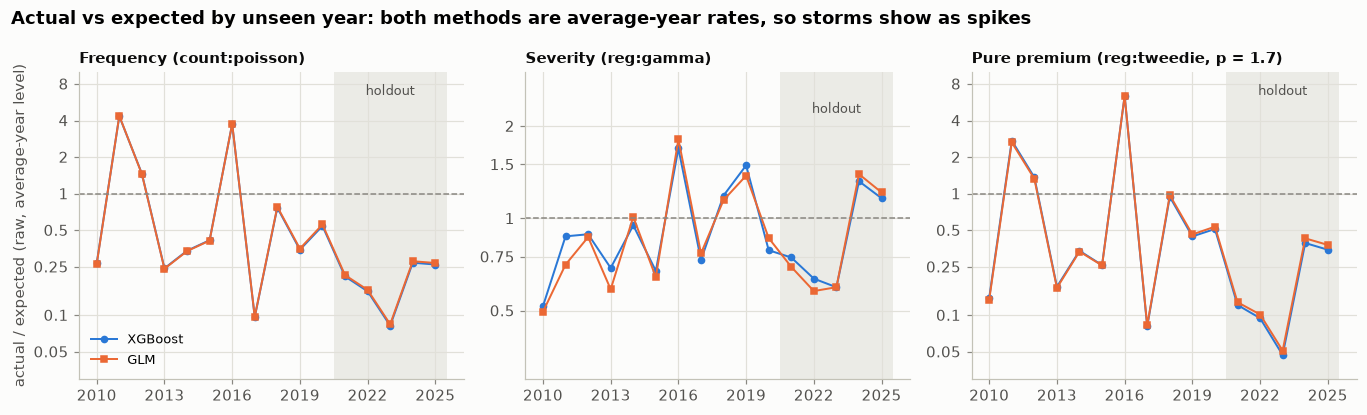

model  frequency         severity         tweedie        
method       GLM XGBoost      GLM XGBoost     GLM XGBoost
year                                                     
2010        0.26    0.27     0.50    0.52    0.13    0.14
2011        4.37    4.34     0.71    0.87    2.65    2.74
2012        1.45    1.46     0.87    0.89    1.33    1.36
2013        0.24    0.24     0.59    0.69    0.17    0.17
2014        0.34    0.34     1.01    0.95    0.33    0.34
2015        0.41    0.41     0.64    0.67    0.26    0.26
2016        3.75    3.74     1.81    1.69    6.39    6.36
2017        0.10    0.10     0.77    0.73    0.08    0.08
2018        0.78    0.77     1.15    1.19    0.97    0.94
2019        0.35    0.35     1.38    1.49    0.46    0.45
2020        0.56    0.54     0.86    0.79    0.54    0.51
2021        0.21    0.21     0.70    0.75    0.13    0.12
2022        0.16    0.16     0.58    0.64    0.10    0.09
2023        0.08    0.08     0.60    0.60    0.05    0.05
2024        0.

In [12]:
# Actual / expected by year: each development year predicted by the model trained on the other 10;
# 2021-2025 by the model trained on 2010-2020. Raw = average-year level, not re-based.
AE = []
for k in KINDS:
    for name in ("XGBoost", "GLM"):
        d = EV[(k, name, "dev-LOYO")][0]
        h = EV[(k, name, "holdout")][0]
        h = h[h.test_year != "pooled"]
        for split, t in (("dev-LOYO", d), ("holdout", h)):
            for _, r in t.iterrows():
                AE.append({"model": k, "method": name, "split": split, "year": int(r["test_year"]),
                           "A/E": r["actual_over_expected"], "improvement %": r["improvement_rebased_pct"], "gini": r["gini"]})
AE = pd.DataFrame(AE)
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))
for ax, k in zip(axes, KINDS):
    for name, c, mk in (("XGBoost", BLUE, "o"), ("GLM", ORANGE, "s")):
        t = AE[(AE.model == k) & (AE.method == name)].sort_values("year")
        ax.plot(t.year, t["A/E"], color=c, marker=mk, ms=4, lw=1.3, label=name)
    ax.axvspan(2020.5, 2025.5, color=GRID, alpha=0.6, lw=0)
    ax.axhline(1, color=MUTED, ls="--", lw=1)
    lo, hi = (0.03, 10) if k != "severity" else (0.3, 3)
    log_axis(ax, lo, hi, ticks=(0.05, 0.1, 0.25, 0.5, 1, 2, 4, 8) if k != "severity" else (0.5, 0.75, 1, 1.5, 2))
    ax.text(2023, hi * 0.8, "holdout", ha="center", va="top", fontsize=8.5, color=INK_2)
    ax.set_title(KLABEL[k], fontsize=10)
    ax.set_xticks(range(2010, 2026, 3))
axes[0].set_ylabel("actual / expected (raw, average-year level)")
axes[0].legend(fontsize=8.5, loc="lower left")
fig.suptitle("Actual vs expected by unseen year: both methods are average-year rates, so storms show as spikes",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "ae_by_year")
plt.show()
print(AE.pivot_table(index="year", columns=["model", "method"], values="A/E").round(2).to_string())

saved reports\figures\08_lift_charts.png


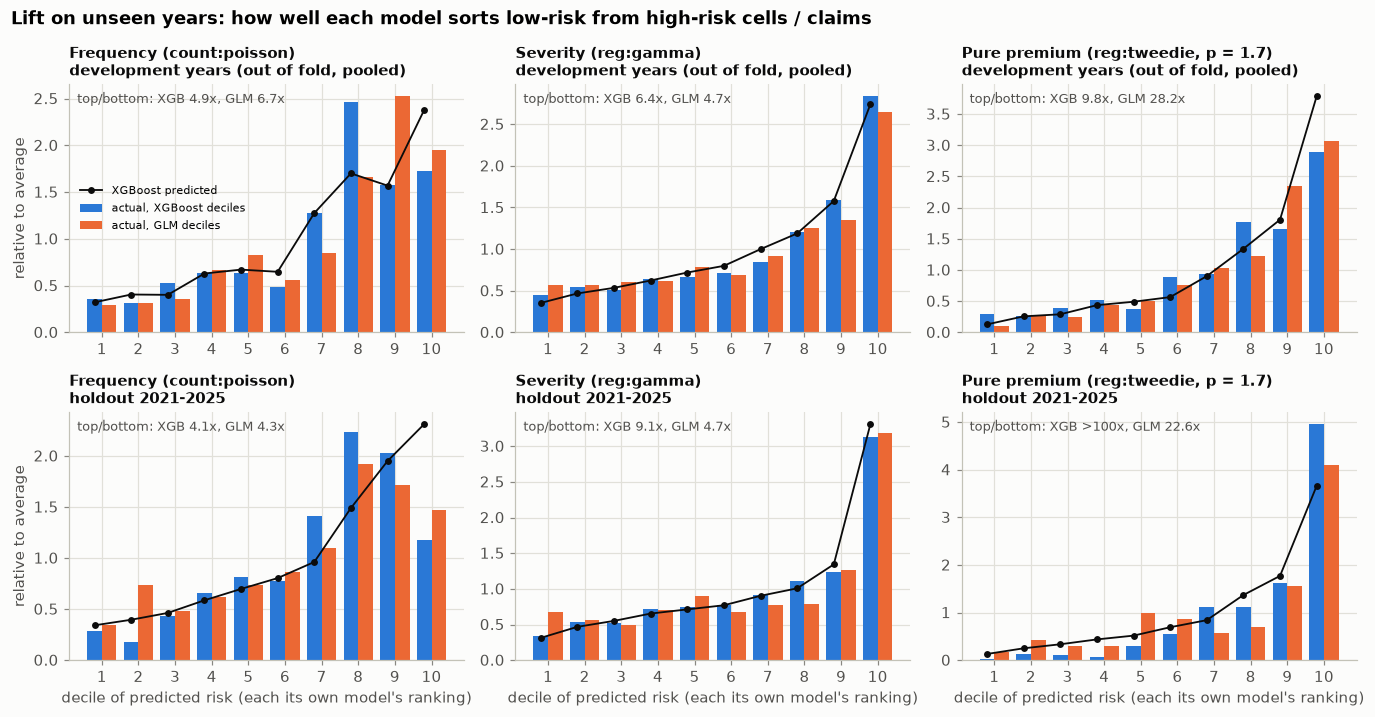

In [13]:
def lift(k, oof, n=10):
    """Deciles of the model's own ranking (level-free relative rate); predictions re-based per year."""
    o = oof.copy()
    tgt = TARGET[k]
    o["rb"] = o["pred"] * o.groupby("year")[tgt].transform("sum") / o.groupby("year")["pred"].transform("sum")
    if k == "frequency":
        t = fg.lift_table(o[tgt], o["rb"], o["exposure"], n, rank_by=o["relative_rate"])
        avg = o[tgt].sum() / o["exposure"].sum()
        return pd.DataFrame({"actual": t["actual_relative_to_average"], "pred": t["pred_freq_per_1000"] / 1000 / avg})
    if k == "severity":
        t = sv.lift_table(o[tgt], o["rb"], rank_by=o["relative_rate"], n=n)
        return pd.DataFrame({"actual": t["actual_relative_to_average"], "pred": t["pred_avg"] / o[tgt].mean()})
    t = pp.lift_table(o[tgt], o["rb"], o["exposure"], rank_by=o["relative_rate"], n=n)
    avg = o[tgt].sum() / o["exposure"].sum()
    return pd.DataFrame({"actual": t["actual_relative"], "pred": t["pred_loss_cost"] / avg})

LIFT = {}
fig, axes = plt.subplots(2, 3, figsize=(12.5, 6.6))
for j, k in enumerate(KINDS):
    for i, split in enumerate(("dev-LOYO", "holdout")):
        ax = axes[i, j]
        lx, lg = lift(k, EV[(k, "XGBoost", split)][1]), lift(k, EV[(k, "GLM", split)][1])
        LIFT[(k, split)] = (lx, lg)
        xs = np.arange(1, 11)
        ax.bar(xs - 0.2, lx["actual"], 0.4, color=BLUE, label="actual, XGBoost deciles")
        ax.bar(xs + 0.2, lg["actual"], 0.4, color=ORANGE, label="actual, GLM deciles")
        ax.plot(xs - 0.2, lx["pred"], color=INK, marker="o", ms=3.5, lw=1.2, label="XGBoost predicted")
        ax.set_xticks(xs)
        ax.set_title(f"{KLABEL[k]}\n{'development years (out of fold, pooled)' if split == 'dev-LOYO' else 'holdout 2021-2025'}",
                     fontsize=9.5)
        tb = lambda t: t["actual"].iloc[-1] / t["actual"].iloc[0]
        fmt = lambda v: ">100x" if v > 100 else f"{v:.1f}x"  # a near-empty bottom decile makes the ratio explode
        ax.text(0.02, 0.97, f"top/bottom: XGB {fmt(tb(lx))}, GLM {fmt(tb(lg))}",
                transform=ax.transAxes, va="top", fontsize=8.5, color=INK_2)
        if j == 0:
            ax.set_ylabel("relative to average")
        if i == 1:
            ax.set_xlabel("decile of predicted risk (each its own model's ranking)")
axes[0, 0].legend(fontsize=7.5, loc="center left")
fig.suptitle("Lift on unseen years: how well each model sorts low-risk from high-risk cells / claims",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "lift_charts")
plt.show()

## 6. A first look inside: gain-based feature importance
The models are saved first: `_dev` (trained 2010–2020, used for the holdout) and `_all` (trained 2010–2025, like the saved GLMs). Importance is read from the `_all` models.

**Gain** = how much the splits on a feature improved the training objective, added up over all trees, shown as a share of the total (one-hot columns such as the 35 county groups are added together).
- It's quick and comes straight from the trees.
- But it measures *training* fit, not held-out value. It favours features with many possible splits, and it says nothing about direction (up or down).

**SHAP values (Milestone 12)** fix most of this: they split each prediction into per-feature contributions, with a sign.

**Result:**
- **Frequency** is driven by year built (45% of gain) and flood zone (21%), the same two drivers as the GLM.
- **Severity** is driven by occupancy (34%), county group (20%) and coverage (12%).
- **Pure premium** spreads gain across county (26%), occupancy (21%), year built (17%), Tidewater and post-FIRM (11% each).

Remember, gain shows *training* use, not held-out value or direction.

saved models/xgb_frequency_dev.ubj (170 trees, years 2010-2020)


saved models/xgb_frequency_all.ubj (170 trees, years 2010-2025)


saved models/xgb_severity_dev.ubj (940 trees, years 2010-2020)


saved models/xgb_severity_all.ubj (940 trees, years 2010-2025)


saved models/xgb_tweedie_dev.ubj (120 trees, years 2010-2020)


saved models/xgb_tweedie_all.ubj (120 trees, years 2010-2025)


xgb_frequency_all.meta.json             1.9 KB
xgb_frequency_all.ubj                 457.8 KB
xgb_frequency_dev.meta.json             1.7 KB
xgb_frequency_dev.ubj                 459.5 KB
xgb_settings.json                       9.5 KB
xgb_severity_all.meta.json              2.7 KB
xgb_severity_all.ubj                 1479.9 KB
xgb_severity_dev.meta.json              2.5 KB
xgb_severity_dev.ubj                 1460.5 KB
xgb_tweedie_all.meta.json               2.8 KB
xgb_tweedie_all.ubj                   278.6 KB
xgb_tweedie_dev.meta.json               2.6 KB
xgb_tweedie_dev.ubj                   272.6 KB

Share of total gain (%), models fitted on all 16 years:
                        frequency  severity  tweedie
construction_band            45.4       5.5     17.3
occupancy_group               6.9      33.6     21.4
county_group                  0.0      20.3     26.1
flood_zone_group             21.2       5.2      7.4
building_coverage_band        8.3      12.0      1.4
coastal_tidal 

saved reports\figures\08_importance.png


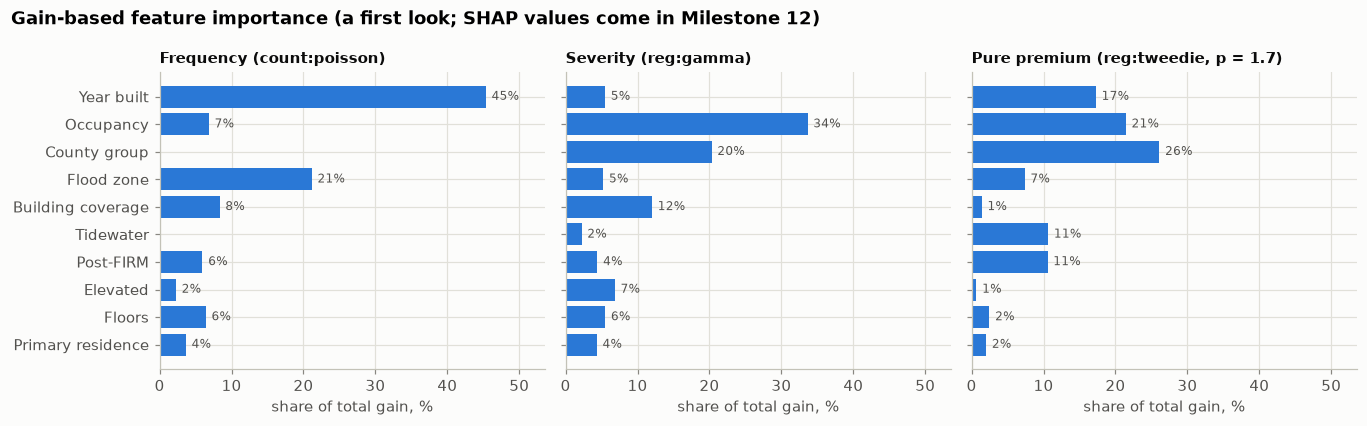

In [14]:
X.cmd_fit_final()          # saves models/xgb_<kind>_{dev,all}.ubj (+ .meta.json)
FINAL = {k: {tag: X.XGBModel.load_model(ROOT / "models" / f"xgb_{k}_{tag}") for tag in ("dev", "all")} for k in KINDS}
# Round trip: the saved dev model predicts the holdout exactly as the model fitted in section 5.
for k in KINDS:
    df, _ = DATA[k]
    test = df[df.year > val.LAST_TRAIN_YEAR]
    assert np.allclose(FINAL[k]["dev"].predict(test), EV[(k, "XGBoost", "holdout")][2]["holdout"].predict(test))
for f in sorted((ROOT / "models").glob("xgb_*")):
    print(f"{f.name:34s} {f.stat().st_size / 1024:8.1f} KB")

IMP = pd.DataFrame({k: X.importance_by_feature(FINAL[k]["all"]) for k in KINDS}).fillna(0.0)
IMP = IMP.loc[IMP.max(axis=1).sort_values(ascending=False).index]
print("\nShare of total gain (%), models fitted on all 16 years:")
print(IMP.round(1).to_string())
IMP.to_csv(REP / "07_xgb_importance.csv")
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.9), sharey=True)
for ax, k in zip(axes, KINDS):
    v = IMP[k].iloc[::-1]
    ax.barh([LABELS[f] for f in v.index], v.to_numpy(), color=BLUE)
    for y, x in enumerate(v.to_numpy()):
        if x > 0:
            ax.text(x + 0.8, y, f"{x:.0f}%", va="center", fontsize=8, color=INK_2)
    ax.set_title(KLABEL[k], fontsize=10)
    ax.set_xlabel("share of total gain, %")
    ax.set_xlim(0, IMP.to_numpy().max() * 1.18)
fig.suptitle("Gain-based feature importance (a first look; SHAP values come in Milestone 12)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "importance")
plt.show()

## 7. Interactions the trees seem to find
**What an interaction is:** the effect of one feature depends on another (e.g. elevation helps more in A/V zones). A GLM without interaction terms assumes every effect simply multiplies. Trees can find interactions on their own.

Two quick measures:
- **Split pairs:** how much gain sits in splits on feature B directly below a split on feature A (a rough sign the tree treats B differently depending on A).
- **Interaction ratio** from two-way partial dependence: PD(a, b) × PD(base, base) ÷ (PD(a, base) × PD(base, b)). **1.00 means the two effects just multiply**, as in a GLM. Above 1, the combination is worse than the product; below 1, better.

Milestone 8's lift chart suggested an elevated × zone effect in severity, so that pair is always shown.

**Result:**
- **Frequency: year built × zone** is the strongest pair (19% of split gain). Built 1960–79 in a B/C/X zone has ratio **0.73**: the old-building penalty is smaller outside the high-risk zones. 2000+ in B/C/X has ratio 1.20 (the newest buildings gain less from being in B/C/X).
- **Severity: coverage × occupancy.** Multi-unit and non-residential buildings with low coverage have ratios 0.5–0.75: their big claims are capped by low limits.
- **Pure premium: year built × occupancy.** Old multi-unit buildings have ratio **2.7–3.0**.
- **Elevated × zone (flagged in Milestone 8):** ratio **1.08**, a small effect. Elevation helps slightly less in B/C/X zones.

These are hints for GLM interaction terms or for SHAP in Milestone 12, not conclusions.


Frequency (count:poisson): parent -> child split pairs, % of all split gain
construction_band x flood_zone_group         19.03
building_coverage_band x flood_zone_group     4.25
building_coverage_band x floors_group         2.70
flood_zone_group x post_firm                  2.58
building_coverage_band x occupancy_group      2.37
floors_group x occupancy_group                2.23
flood_zone_group x occupancy_group            1.86
construction_band x occupancy_group           1.84



Severity (reg:gamma): parent -> child split pairs, % of all split gain
county_group x occupancy_group              7.58
building_coverage_band x occupancy_group    6.71
county_group x flood_zone_group             4.66
building_coverage_band x county_group       3.93
county_group x elevated                     3.56
construction_band x county_group            3.13
county_group x post_firm                    2.85
elevated x floors_group                     2.45



Pure premium (reg:tweedie, p = 1.7): parent -> child split pairs, % of all split gain
construction_band x occupancy_group    9.20
construction_band x county_group       7.04
county_group x occupancy_group         6.70
county_group x flood_zone_group        6.17
coastal_tidal x construction_band      5.96
occupancy_group x post_firm            4.79
coastal_tidal x county_group           3.88
flood_zone_group x occupancy_group     2.80


saved reports\figures\08_interactions.png


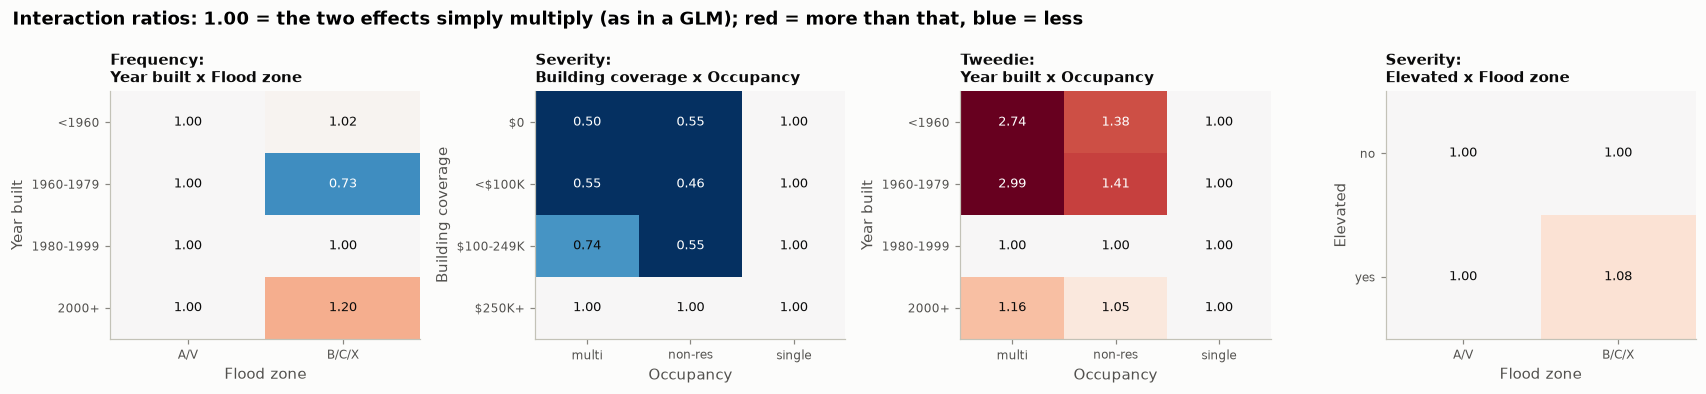


frequency: Year built x Flood zone -- two-way relativities (vs 1980-1999, A/V high risk)
               A/V high risk  B/C/X moderate-low risk
before 1960             2.06                     1.30
1960-1979               2.13                     0.98
1980-1999               1.00                     0.62
2000 or later           0.74                     0.56

severity: Building coverage x Occupancy -- two-way relativities (vs $250K or more, single-unit residential)
                    multi-unit residential  non-residential  single-unit residential
$0 (contents only)                    0.42             0.88                     0.47
under $100K                           0.73             1.16                     0.74
$100K-$249K                           1.16             1.62                     0.87
$250K or more                         1.79             3.42                     1.00

tweedie: Year built x Occupancy -- two-way relativities (vs 1980-1999, single-unit residential)
         

In [15]:
INTER = {}
for k in KINDS:
    INTER[k] = X.interaction_pairs(FINAL[k]["all"], top=8)
    print(f"\n{KLABEL[k]}: parent -> child split pairs, % of all split gain")
    print(INTER[k].round(2).to_string())
pd.concat({k: v for k, v in INTER.items()}).rename("pct_of_split_gain").to_csv(REP / "07_xgb_interactions.csv")

BASE = {"flood_zone_group": "A/V high risk", "construction_band": "1980-1999", "building_coverage_band": "$250K or more",
        "occupancy_group": "single-unit residential", "elevated": "False", "post_firm": "False",
        "primary_residence": "True", "floors_group": "2", "coastal_tidal": "True"}
def top_pair(k):
    for p in INTER[k].index:
        a, b = p.split(" x ")
        if "county_group" not in (a, b):
            return a, b
pairs = [(k, *top_pair(k)) for k in KINDS]
if ("severity", "elevated", "flood_zone_group") not in pairs and ("severity", "flood_zone_group", "elevated") not in pairs:
    pairs.append(("severity", "elevated", "flood_zone_group"))   # flagged in Milestone 8 (bottom decile)
fig, axes = plt.subplots(1, len(pairs), figsize=(3.9 * len(pairs), 3.6))
TW = []
for ax, (k, a, b) in zip(np.atleast_1d(axes), pairs):
    df, _ = DATA[k]
    rel, ratio = X.two_way_interaction(FINAL[k]["all"], df, a, b, BASE[a], BASE[b], WEIGHT[k])
    TW.append((k, a, b, rel, ratio))
    r = ratio.astype(float)
    im = ax.imshow(np.log(r.to_numpy()), cmap="RdBu_r", norm=TwoSlopeNorm(0, -0.5, 0.5), aspect="auto")
    for (yi, xi), v in np.ndenumerate(r.to_numpy()):
        ax.text(xi, yi, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(np.log(v)) > 0.3 else INK)  # light text on dark cells
    ax.set_xticks(range(r.shape[1]))
    ax.set_xticklabels([SHORT.get(l, l) for l in r.columns], fontsize=8)
    ax.set_yticks(range(r.shape[0]))
    ax.set_yticklabels([SHORT.get(l, l) for l in r.index], fontsize=8)
    ax.set_xlabel(LABELS[b])
    ax.set_ylabel(LABELS[a])
    ax.set_title(f"{k.capitalize()}:\n{LABELS[a]} x {LABELS[b]}", fontsize=9.5)
    ax.grid(False)
fig.suptitle("Interaction ratios: 1.00 = the two effects simply multiply (as in a GLM); red = more than that, blue = less",
             x=0.01, ha="left", fontweight="bold", fontsize=11.5)
fig.tight_layout()
save(fig, "interactions")
plt.show()
for k, a, b, rel, ratio in TW:
    print(f"\n{k}: {LABELS[a]} x {LABELS[b]} -- two-way relativities (vs {BASE[a]}, {BASE[b]})")
    print(rel.astype(float).round(2).to_string())

## 8. Pure premium: XGBoost Tweedie vs XGBoost frequency × severity
Milestone 9 kept the GLM Tweedie as a challenger only after checking it against frequency × severity with a **double lift** and a **segment balance** check, and asked that an XGBoost Tweedie pass the same checks. Here:
- **XGBoost freq × sev** = frequency XGBoost × severity XGBoost × ICC bridge × off-balance (no county factor: any geography is inside the trees).
- All four pure-premium models are scored at the common Tweedie p = 1.5 yardstick on the same cells. GLM freq × sev is shown *without* the county factor here. Milestone 11 adds it.

**Result:**
- **Score:** the **XGBoost Tweedie scores best** (dev 17.4%, holdout 20.8%), then XGBoost freq × sev (17.0%, 13.4%), the GLM Tweedie (13.5%, 10.4%) and GLM freq × sev without the county factor (13.2%, 6.8%).
- **But the XGBoost Tweedie fails the same checks as the GLM Tweedie.**
  - **Double lift:** where the two XGBoost structures disagree, freq × sev is right. End-decile error is **0.24 vs 0.78**. In decile 10 the Tweedie predicts 1.60× while actual is 0.57×.
  - **Segments (out of fold):** it under-predicts multi-unit buildings (A/E 1.49) and over-predicts policies under $100K (A/E 0.59) and contents-only policies (0.71).
- So Milestone 9's conclusion carries over: **frequency × severity stays the recommended structure**, and the Tweedie is a challenger.
- **XGBoost freq × sev balances segments better than the GLM in some places:** multi-unit 1.15 vs 1.33, contents-only 0.97 vs 1.61.
- **Worse in one:** buildings from **2000 or later are over-predicted** (A/E 0.70 vs 0.95). The likely reason: XGBoost's 2000+ frequency effect is 0.37× vs the GLM's 0.23×. Early stopping at 170 small steps shrinks extreme effects toward the average. Milestone 11 should check this.

In [16]:
# Pure premium on unseen years, four ways, all scored at the common Tweedie p = 1.5 yardstick
# on the same cell rows: XGBoost freq x sev, XGBoost Tweedie, GLM freq x sev (no county factor), GLM Tweedie.
PP_SC, PP_OOF = [], []
splits = [(y, tr, te) for y, tr, te in val.leave_one_year_out(cells, val.DEV_YEARS)] + \
         [("holdout",) + tuple(val.time_holdout(cells))]
for label, tr, te in splits:
    yrs = sorted(tr.year.unique())
    un_tr = X._unm(unm, yrs)
    split = "holdout" if label == "holdout" else "dev-LOYO"
    fx = EV[("frequency", "XGBoost", split)][2][label]
    sx = EV[("severity", "XGBoost", split)][2][label]
    combo = X.combine_freq_sev(fx, sx, tr, claims_all[claims_all.year.isin(yrs)], un_tr)
    glm = pp.fit_combined(raw_cells[raw_cells.year.isin(yrs)], claims_all[claims_all.year.isin(yrs)], FF, SF, FB, SB)
    preds = {"XGBoost freq x sev": combo.predict(te), "XGBoost Tweedie": EV[("tweedie", "XGBoost", split)][2][label].predict(te),
             "GLM freq x sev": glm.predict(te, county=False),
             "GLM Tweedie": EV[("tweedie", "GLM", split)][2][label].predict(te)}
    o = te[["year", "exposure", "claims", X.LOSS, *X.ALL_FEATURES]].copy()
    for name, p in preds.items():
        o[name] = p
        groups = [(label, te, p)] if split == "dev-LOYO" else \
            [(int(y), te[te.year == y], p[(te.year == y).to_numpy()]) for y in sorted(te.year.unique())] + [("pooled", te, p)]
        for g, t, pr in groups:
            PP_SC.append({"model": name, "split": split, "test_year": g,
                          **X.score(t, pr, "tweedie", tr, None, un_tr, X._unm(unm, t.year.unique()))})
    o["split"] = split
    PP_OOF.append(o)
PP_SC, PP_OOF = pd.DataFrame(PP_SC), pd.concat(PP_OOF, ignore_index=True)
d = PP_SC[PP_SC.split == "dev-LOYO"]
h = PP_SC[(PP_SC.split == "holdout") & (PP_SC.test_year == "pooled")].set_index("model")
pp_tbl = pd.DataFrame({
    "dev-LOYO mean %": d.groupby("model").improvement_rebased_pct.mean(),
    "normal yrs %": d[~d.test_year.isin(val.CAT_YEARS)].groupby("model").improvement_rebased_pct.mean(),
    "cat yrs %": d[d.test_year.isin(val.CAT_YEARS)].groupby("model").improvement_rebased_pct.mean(),
    "dev Gini": d.groupby("model").gini.mean(),
    "holdout %": h["improvement_rebased_pct"], "holdout Gini": h["gini"], "holdout raw A/E": h["actual_over_expected"]})
print(pp_tbl.round(3).to_string())

                    dev-LOYO mean %  normal yrs %  cat yrs %  dev Gini  holdout %  holdout Gini  holdout raw A/E
model                                                                                                           
GLM Tweedie                  13.536        14.439     11.128     0.501     10.423         0.475            0.217
GLM freq x sev               13.165        12.263     15.571     0.493      6.823         0.424            0.202
XGBoost Tweedie              17.441        20.013     10.584     0.561     20.845         0.645            0.201
XGBoost freq x sev           16.996        17.231     16.369     0.545     13.392         0.518            0.195


        losses_relative  a_relative  b_relative  ratio_a_over_b
decile                                                         
1                  1.03        0.51        1.35            0.38
2                  1.13        0.80        1.31            0.61
3                  0.93        0.74        1.01            0.74
4                  2.06        1.16        1.36            0.85
5                  0.90        0.96        0.99            0.97
6                  1.19        1.15        1.06            1.09
7                  0.84        1.03        0.83            1.23
8                  0.71        0.98        0.70            1.40
9                  0.66        1.07        0.66            1.62
10                 0.57        1.60        0.72            2.22
mean |model - actual| in the two end deciles: Tweedie 0.78, freq x sev 0.24


saved reports\figures\08_double_lift.png


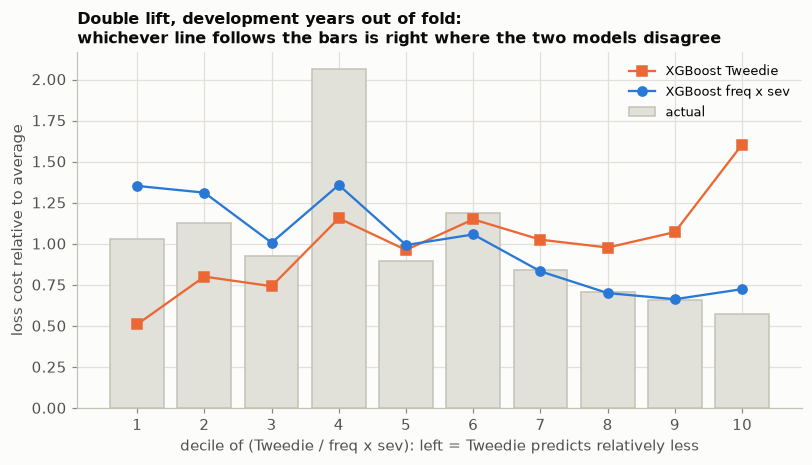

          feature                   level  in-sample XGB freq x sev  in-sample XGB Tweedie  in-sample GLM freq x sev (M9)  in-sample GLM Tweedie (M9)  out-of-fold XGB freq x sev  out-of-fold XGB Tweedie  out-of-fold GLM freq x sev  out-of-fold GLM Tweedie
        Occupancy  multi-unit residential                      1.17                   1.59                           1.33                        1.22                        1.15                     1.49                        1.33                     1.13
        Occupancy         non-residential                      0.90                   0.78                           0.74                        0.50                        0.77                     0.64                        0.67                     0.44
        Occupancy single-unit residential                      0.99                   0.97                           1.01                        1.17                        1.02                     1.01                        1.02  

In [17]:
# Double lift on the development years (out of fold, re-based per year): XGBoost Tweedie vs XGBoost freq x sev.
dv = PP_OOF[PP_OOF.split == "dev-LOYO"].copy()
for c in ["XGBoost freq x sev", "XGBoost Tweedie", "GLM freq x sev", "GLM Tweedie"]:
    dv[c + " rb"] = dv[c] * dv.groupby("year")[X.LOSS].transform("sum") / dv.groupby("year")[c].transform("sum")
DL = pp.double_lift(dv[X.LOSS], dv["XGBoost Tweedie rb"], dv["XGBoost freq x sev rb"], dv["exposure"])
end = DL.iloc[[0, -1]]
err = {"Tweedie": float((end["a_relative"] - end["losses_relative"]).abs().mean()),
       "freq x sev": float((end["b_relative"] - end["losses_relative"]).abs().mean())}
print(DL[["losses_relative", "a_relative", "b_relative", "ratio_a_over_b"]].round(2).to_string())
print(f"mean |model - actual| in the two end deciles: Tweedie {err['Tweedie']:.2f}, freq x sev {err['freq x sev']:.2f}")
fig, ax = plt.subplots(figsize=(8.5, 4.2))
xs = DL.index.to_numpy()
ax.bar(xs, DL["losses_relative"], color=GRID, edgecolor=AXIS, label="actual")
ax.plot(xs, DL["a_relative"], color=ORANGE, marker="s", lw=1.5, label="XGBoost Tweedie")
ax.plot(xs, DL["b_relative"], color=BLUE, marker="o", lw=1.5, label="XGBoost freq x sev")
ax.set_xticks(xs)
ax.set_xlabel("decile of (Tweedie / freq x sev): left = Tweedie predicts relatively less")
ax.set_ylabel("loss cost relative to average")
ax.legend(fontsize=8.5)
ax.set_title("Double lift, development years out of fold:\nwhichever line follows the bars is right where the two models disagree",
             fontsize=10.5, loc="left")
save(fig, "double_lift")
plt.show()

# Segment balance (the Milestone 9 check): in-sample A/E by level, re-based per year, all-years models,
# next to Milestone 9's GLM numbers. Out-of-fold (development years) versions alongside.
allfs = X.combine_freq_sev(FINAL["frequency"]["all"], FINAL["severity"]["all"], cells, claims_all, unm.sum())
mc = cells.copy()
for name, pr in (("XGB freq x sev", allfs.predict(mc)), ("XGB Tweedie", FINAL["tweedie"]["all"].predict(mc))):
    mc[name] = pr * mc.groupby("year")[X.LOSS].transform("sum") / pd.Series(pr, index=mc.index).groupby(mc["year"]).transform("sum")
m9 = pd.read_csv(REP / "06_segment_balance.csv")
bal = []
for f in ["occupancy_group", "building_coverage_band", "flood_zone_group", "construction_band", "elevated"]:
    g = mc.groupby(f, observed=True)[[X.LOSS, "XGB freq x sev", "XGB Tweedie"]].sum()
    go = dv.groupby(f, observed=True)[[X.LOSS, "XGBoost freq x sev rb", "XGBoost Tweedie rb", "GLM freq x sev rb", "GLM Tweedie rb"]].sum()
    for lvl in g.index:
        r9 = m9[(m9.feature == LABELS[f]) & (m9.level == str(lvl))]
        bal.append({"feature": LABELS[f], "level": str(lvl),
                    "in-sample XGB freq x sev": g.loc[lvl, X.LOSS] / g.loc[lvl, "XGB freq x sev"],
                    "in-sample XGB Tweedie": g.loc[lvl, X.LOSS] / g.loc[lvl, "XGB Tweedie"],
                    "in-sample GLM freq x sev (M9)": r9.iloc[0, 2] if len(r9) else np.nan,
                    "in-sample GLM Tweedie (M9)": r9.iloc[0, 3] if len(r9) else np.nan,
                    "out-of-fold XGB freq x sev": go.loc[lvl, X.LOSS] / go.loc[lvl, "XGBoost freq x sev rb"],
                    "out-of-fold XGB Tweedie": go.loc[lvl, X.LOSS] / go.loc[lvl, "XGBoost Tweedie rb"],
                    "out-of-fold GLM freq x sev": go.loc[lvl, X.LOSS] / go.loc[lvl, "GLM freq x sev rb"],
                    "out-of-fold GLM Tweedie": go.loc[lvl, X.LOSS] / go.loc[lvl, "GLM Tweedie rb"]})
balance = pd.DataFrame(bal)
print(balance.round(2).to_string(index=False))
balance.to_csv(REP / "07_xgb_segment_balance.csv", index=False)

## 9. Two sensitivity checks
- **Severity large losses:** the chosen treatment is the GLM's (uncapped, load 1.0). Capping at each training fold's P99 with a flat load is shown for comparison.
- **Frequency year levels:** the year part of `base_margin` comes from a year-only model. One round of *back-fitting* (re-estimate each year's level from the fitted model's A/E, refit) is shown. If it barely moves the score, the simple version is fine.

**Result:**
- **Severity:** capping at P99 + load is worse (25.16% vs 25.43%), so uncapped stays, as for the GLM.
- **Frequency:** back-fitting the year levels changes the score by +0.01 points, so the simple year-only levels stay.

In [18]:
sens = []
s, (df, u) = S["severity"], DATA["severity"]
for label, cq in (("uncapped (chosen, as the GLM)", None), ("cap at P99 + load", 0.99)):
    sc, _, mods = X.evaluate(df, "severity", s["params"], s["n_rounds"], s["features"], s["monotone"], cap_quantile=cq)
    sens.append({"model": "severity", "variant": label, "dev-LOYO mean %": sc.improvement_rebased_pct.mean(),
                 "avg load": np.mean([m.load for m in mods.values()])})
s, (df, u) = S["frequency"], DATA["frequency"]
for label, bf in (("year levels from the year-only model (chosen)", 0), ("+ one back-fitting round", 1)):
    sc, _, _ = X.evaluate(df, "frequency", s["params"], s["n_rounds"], s["features"], s["monotone"], year_backfit=bf)
    sens.append({"model": "frequency", "variant": label, "dev-LOYO mean %": sc.improvement_rebased_pct.mean()})
sens = pd.DataFrame(sens)
print(sens.round(3).to_string(index=False))

    model                                       variant  dev-LOYO mean %  avg load
 severity                 uncapped (chosen, as the GLM)           25.435     1.000
 severity                             cap at P99 + load           25.156     1.033
frequency year levels from the year-only model (chosen)            6.752       NaN
frequency                      + one back-fitting round            6.765       NaN


## 10. Save tables and settings
- **Committed:** `models/xgb_settings.json` (small, readable: features, encoding, constraints, hyperparameters, tree counts, tuning summary, held-out scores) and the `models/xgb_*.meta.json` companions.
- **Not committed:** the tree files `models/xgb_*.ubj`. They're gitignored, rebuilt with `.venv\Scripts\python.exe src\models\xgb_models.py fit-final`, and loaded with `xgb_models.XGBModel.load_model("models/xgb_frequency_all")`.

In [19]:
heldout = pd.concat([sc.assign(model=k, method=name, split=split) for (k, name, split), (sc, _, _) in EV.items()],
                    ignore_index=True)
heldout.to_csv(REP / "07_xgb_heldout_scores.csv", index=False)
preview.to_csv(REP / "07_xgb_preview_vs_glm.csv", index=False)
pp_tbl.to_csv(REP / "07_xgb_pure_premium_preview.csv")
PP_SC.to_csv(REP / "07_xgb_pure_premium_scores.csv", index=False)
AE.to_csv(REP / "07_xgb_ae_by_year.csv", index=False)
DL.to_csv(REP / "07_xgb_double_lift.csv")
pd_tbl.to_csv(REP / "07_xgb_monotone_pd.csv", index=False)
sens.to_csv(REP / "07_xgb_sensitivity.csv", index=False)

S = X.read_settings()
for k in KINDS:
    r = preview[(preview.model == k) & (preview.method == "XGBoost")].iloc[0]
    S[k]["heldout"] = {"dev_loyo_mean_pct": r["dev-LOYO mean %"], "dev_loyo_gini": r["dev Gini"],
                       "holdout_2021_2025_pct": r["holdout %"], "holdout_gini": r["holdout Gini"],
                       "holdout_raw_ae": r["holdout raw A/E"]}
    S[k]["saved_models"] = {"dev": f"models/xgb_{k}_dev.ubj (trained 2010-2020; for the holdout)",
                            "all": f"models/xgb_{k}_all.ubj (trained 2010-2025; like the saved GLMs)"}
S["notes"] = {"created_by": "notebooks/08_xgboost.ipynb (Milestone 10)",
              "load": "xgb_models.XGBModel.load_model('models/xgb_<kind>_<dev|all>')",
              "rebuild_boosters": r".venv\Scripts\python.exe src\models\xgb_models.py fit-final",
              "xgboost_version": xgb.__version__,
              "area_level_only": "Predictions describe groups of similar insured buildings, never one property."}
X.write_settings(S)
print("saved models/xgb_settings.json and reports/07_xgb_*.csv")

saved models/xgb_settings.json and reports/07_xgb_*.csv


## Summary
- **Tuned fairly:** 300 random settings × 11 development years (2010–2020 only). Early stopping is on the cross-validation mean, there's a separate search per geography variant, and the rules were written before running. 2021–2025 was touched once, at the end.
- **Final settings:** frequency depth 5, lr 0.023, 170 trees, no geography, unconstrained. Severity depth 5, lr 0.016, 940 trees, Tidewater + county group, unconstrained. Tweedie depth 5, lr 0.021, 120 trees, Tidewater + county group, **monotone constraints**.
- **Held-out preview:** XGBoost beats the GLMs on every model. Frequency 6.75% vs 5.58% (holdout 4.3% vs 2.2%), severity 25.4% vs 19.2% (holdout 23.7% vs 16.7%), Tweedie 17.4% vs 13.5% (holdout 20.8% vs 10.4%). Exceptions: frequency is worse in hurricane years and has a flatter top-to-bottom lift.
- **Question 7 (geography):** XGBoost finds **no useful geography for frequency** (county: worse in 10 of 11 years) but **real county and Tidewater signal for severity** (+2.0 points, holdout confirms). That's consistent with Milestone 9's credibility result.
- **Monotone constraints:** cost-free for the Tweedie (used). Too costly for severity (−0.54). For frequency they're better on average but worse in 9 of 11 years, so not used; the unconstrained elevated effect (1.01) is a defensibility gap to revisit.
- **Pure premium:** the XGBoost Tweedie scores best but fails the double lift and segment checks, like the GLM Tweedie. **Frequency × severity remains the recommended structure.**
- **Next:** Milestone 11's full GLM-vs-XGBoost comparison on all 16 years (significance across years, double lifts, segment checks, the 2000+ over-prediction, the frequency constraint question). Then Milestone 12: SHAP.